# Prediksi Kecelakaan Lalu Lintas
---
## 1. Business Understanding

### 1.1 Latar belakang, masalah, dan solusi
1. **Latar Belakang**: Instansi pengelola lalu lintas, kepolisian, dan otoritas keselamatan jalan raya ingin memprediksi potensi terjadinya kecelakaan lalu lintas (Accident) berdasarkan kondisi lingkungan, karakteristik jalan, kendaraan, serta profil pengemudi.
2. **Masalah**: Instansi  pengelola lalu lintas, kepolisian, dan otoritas keselamatan jalan raya membutuhkan sistem untuk memprediksi sistem potensi terjadinya kecelakaan lalu lintas berdasarkan kondisi lingkungan, akrakteristik jalan, kendaraan, serta    profil pengemudi untuk mendukung deteksi resiko dini.
3. **Solusi**: Membangun model *machine learning* dengan algoritma **LightGBM** dengan memanfaatkan data historis lalu lintas untuk membantu deteksi resiko dini, penempatan patroli, serta rekayasa lalu lintas yang lebih baik.

### 1.2 Deskripsi Kolom Dataset `dataset_traffic_accident_prediction1.csv`
| **Nama Kolom** | **Tipe Data** | **Keterangan** |
| :-- | :-- | :-- |
| `Weather` | `str` | cuaca saat ini |
| `Road_Type` | `str` | jenis jalan |
| `Time_of_Day` | `str` | waktu kejadian |
| `Traffic_Density` | `float64` | kepadatan lalu lintas |
| `Speed_Limit` | `float64` | batas kecepatan jalan |
| `Number_of_Vehicles` | `float64` | jumlah kendaraan yang terlibat |
| `Driver_Alcohol` | `float64` | status alkohol pengemudi |
| `Accident_Severity` | `str` | tingkat keparahan kecelakaan |
| `Road_Condition` | `str` | kondisi permukaan jalan |
| `Vehicle_Type` | `str` | tipe kendaraan |
| `Driver_Age` | `float64` | umur pengemudi |
| `Driver_Experience` | `float64` | pengalamanm mengemudi |
| `Road_Light_Condition` | `str` | kondisi pencahayaan jalan |
| `Accident` | `float64` | target klasifikasi (0.0 = tidak terjadi kecelakaan, 1.0 = terjadi kecelakaan) |

---
## 2. Data Preparation

### 2.1 Import library

In [200]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### 2.2 Load dataset

In [201]:
df = pd.read_csv('dataset_traffic_accident_prediction1.csv', na_values=['NA', 'N/A', '', ' '])
df.columns = df.columns.str.strip()

### 2.3 Menampilkan data teratas dan data terbawah

In [202]:
df.head()

,Weather,Road_Type,Time_of_Day,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Accident_Severity,Road_Condition,Vehicle_Type,Driver_Age,Driver_Experience,Road_Light_Condition,Accident
0,Rainy,City Road,Morning,1.0,100.0,5.0,0.0,NaN,Wet,Car,51.0,48.0,Artificial Light,0.0
1,Clear,Rural Road,Night,NaN,120.0,3.0,0.0,Moderate,Wet,Truck,49.0,43.0,Artificial Light,0.0
2,Rainy,Highway,Evening,1.0,60.0,4.0,0.0,Low,Icy,Car,54.0,52.0,Artificial Light,0.0
3,Clear,City Road,Afternoon,2.0,60.0,3.0,0.0,Low,Under Construction,Bus,34.0,31.0,Daylight,0.0
4,Rainy,Highway,Morning,1.0,195.0,11.0,0.0,Low,Dry,Car,62.0,55.0,Artificial Light,1.0


In [203]:
df.tail()

,Weather,Road_Type,Time_of_Day,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Accident_Severity,Road_Condition,Vehicle_Type,Driver_Age,Driver_Experience,Road_Light_Condition,Accident
835,Clear,Highway,Night,2.0,30.0,4.0,0.0,Low,Dry,Car,23.0,15.0,Daylight,0.0
836,Rainy,Rural Road,Evening,2.0,60.0,4.0,0.0,Low,Dry,Motorcycle,52.0,46.0,Daylight,1.0
837,Foggy,Highway,Evening,NaN,30.0,4.0,1.0,High,Dry,Car,NaN,34.0,Artificial Light,NaN
838,Foggy,Highway,Afternoon,2.0,60.0,3.0,0.0,Low,Dry,Car,25.0,19.0,Artificial Light,0.0
839,Clear,Highway,Afternoon,1.0,60.0,4.0,0.0,Low,Dry,Motorcycle,29.0,21.0,Artificial Light,0.0


### 2.4 Menampilkan informasi data

In [204]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 840 entries, 0 to 839
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Weather               798 non-null    str    
 1   Road_Type             798 non-null    str    
 2   Time_of_Day           798 non-null    str    
 3   Traffic_Density       798 non-null    float64
 4   Speed_Limit           798 non-null    float64
 5   Number_of_Vehicles    798 non-null    float64
 6   Driver_Alcohol        798 non-null    float64
 7   Accident_Severity     798 non-null    str    
 8   Road_Condition        798 non-null    str    
 9   Vehicle_Type          798 non-null    str    
 10  Driver_Age            798 non-null    float64
 11  Driver_Experience     798 non-null    float64
 12  Road_Light_Condition  798 non-null    str    
 13  Accident              798 non-null    float64
dtypes: float64(7), str(7)
memory usage: 92.0 KB


### 2.5 Memeriksa jumlah data, missing value, dan data duplikat

In [205]:
print(f'jumlah data: {df.size}')
print(f'\njumlah missing value: {df.isnull().sum().sum()}')
print(f'--- missing value setipa kolom --- \n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'\njumlah data duplikat: {df.duplicated().sum()}')

jumlah data: 11760

jumlah missing value: 588
--- missing value setipa kolom --- 
Weather                 42
Road_Type               42
Time_of_Day             42
Traffic_Density         42
Speed_Limit             42
Number_of_Vehicles      42
Driver_Alcohol          42
Accident_Severity       42
Road_Condition          42
Vehicle_Type            42
Driver_Age              42
Driver_Experience       42
Road_Light_Condition    42
Accident                42
dtype: int64

jumlah data duplikat: 14


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Menampilkan deskripsi data

In [206]:
df.describe()

,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Driver_Age,Driver_Experience,Accident
count,798.000000,798.000000,798.000000,798.000000,798.000000,798.000000,798.000000
mean,1.001253,71.050125,3.286967,0.160401,43.259398,38.981203,0.299499
std,0.784894,32.052458,2.017267,0.367208,15.129856,15.273201,0.458326
min,0.000000,30.000000,1.000000,0.000000,18.000000,9.000000,0.000000
25%,0.000000,50.000000,2.000000,0.000000,30.000000,26.000000,0.000000
50%,1.000000,60.000000,3.000000,0.000000,43.000000,39.000000,0.000000
75%,2.000000,80.000000,4.000000,0.000000,56.000000,52.750000,1.000000
max,2.000000,213.000000,14.000000,1.000000,69.000000,69.000000,1.000000


### 3.2 Analisis outlier dengan IQR dan Z-Score

In [207]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
outliers = []

for col in numeric_cols:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - (1.5 * iqr)
        upper = q3 + (1.5 * iqr)
        mean = df[col].mean()
        median = df[col].median()
        std = df[col].std()
        skew = df[col].skew()
        min = df[col].min()
        max = df[col].max()
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'stnadard deviasi': std,
            'kemiringan': skew,
            'min': min,
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': max,
            'oulier iqr': outlier_iqr.shape[0],
            'outlier z-score': outlier_z.shape[0]
        })
        
pd.DataFrame(outliers)

,nama kolom,mean,stnadard deviasi,kemiringan,min,q1,median,q3,max,oulier iqr,outlier z-score
0,Traffic_Density,1.001253,0.784894,-0.002200,0.0,0.0,1.0,2.00,2.0,0,0
1,Speed_Limit,71.050125,32.052458,1.853672,30.0,50.0,60.0,80.00,213.0,25,25
2,Number_of_Vehicles,3.286967,2.017267,2.125287,1.0,2.0,3.0,4.00,14.0,23,23
3,Driver_Alcohol,0.160401,0.367208,1.854276,0.0,0.0,0.0,0.00,1.0,128,0
4,Driver_Age,43.259398,15.129856,0.062291,18.0,30.0,43.0,56.00,69.0,0,0
5,Driver_Experience,38.981203,15.273201,0.006514,9.0,26.0,39.0,52.75,69.0,0,0
6,Accident,0.299499,0.458326,0.877127,0.0,0.0,0.0,1.00,1.0,0,0


### 3.3 Visualisasi outlier dengan boxplot

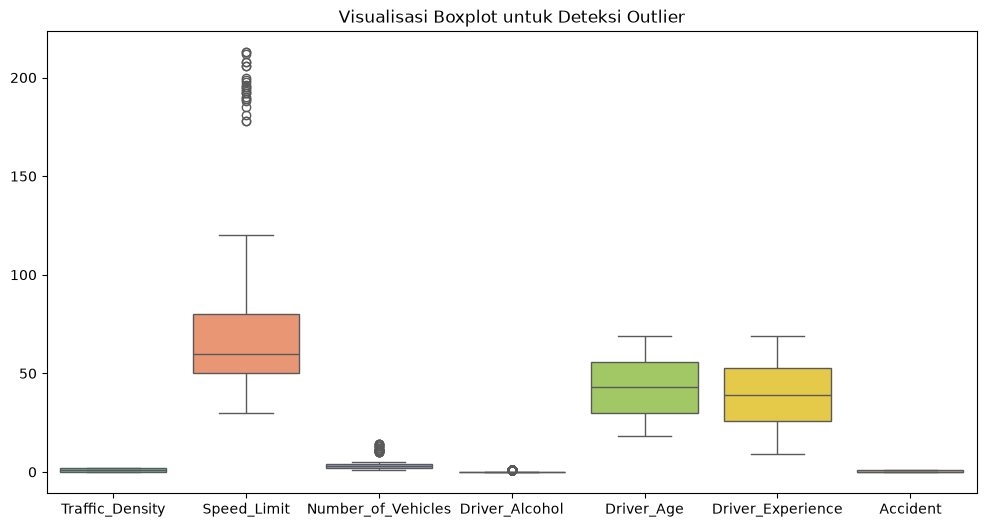

In [208]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numeric_cols], palette='Set2')
plt.title('Visualisasi Boxplot untuk Deteksi Outlier')
plt.show()

### 3.4 Visualisasi distribusi kolom numerik

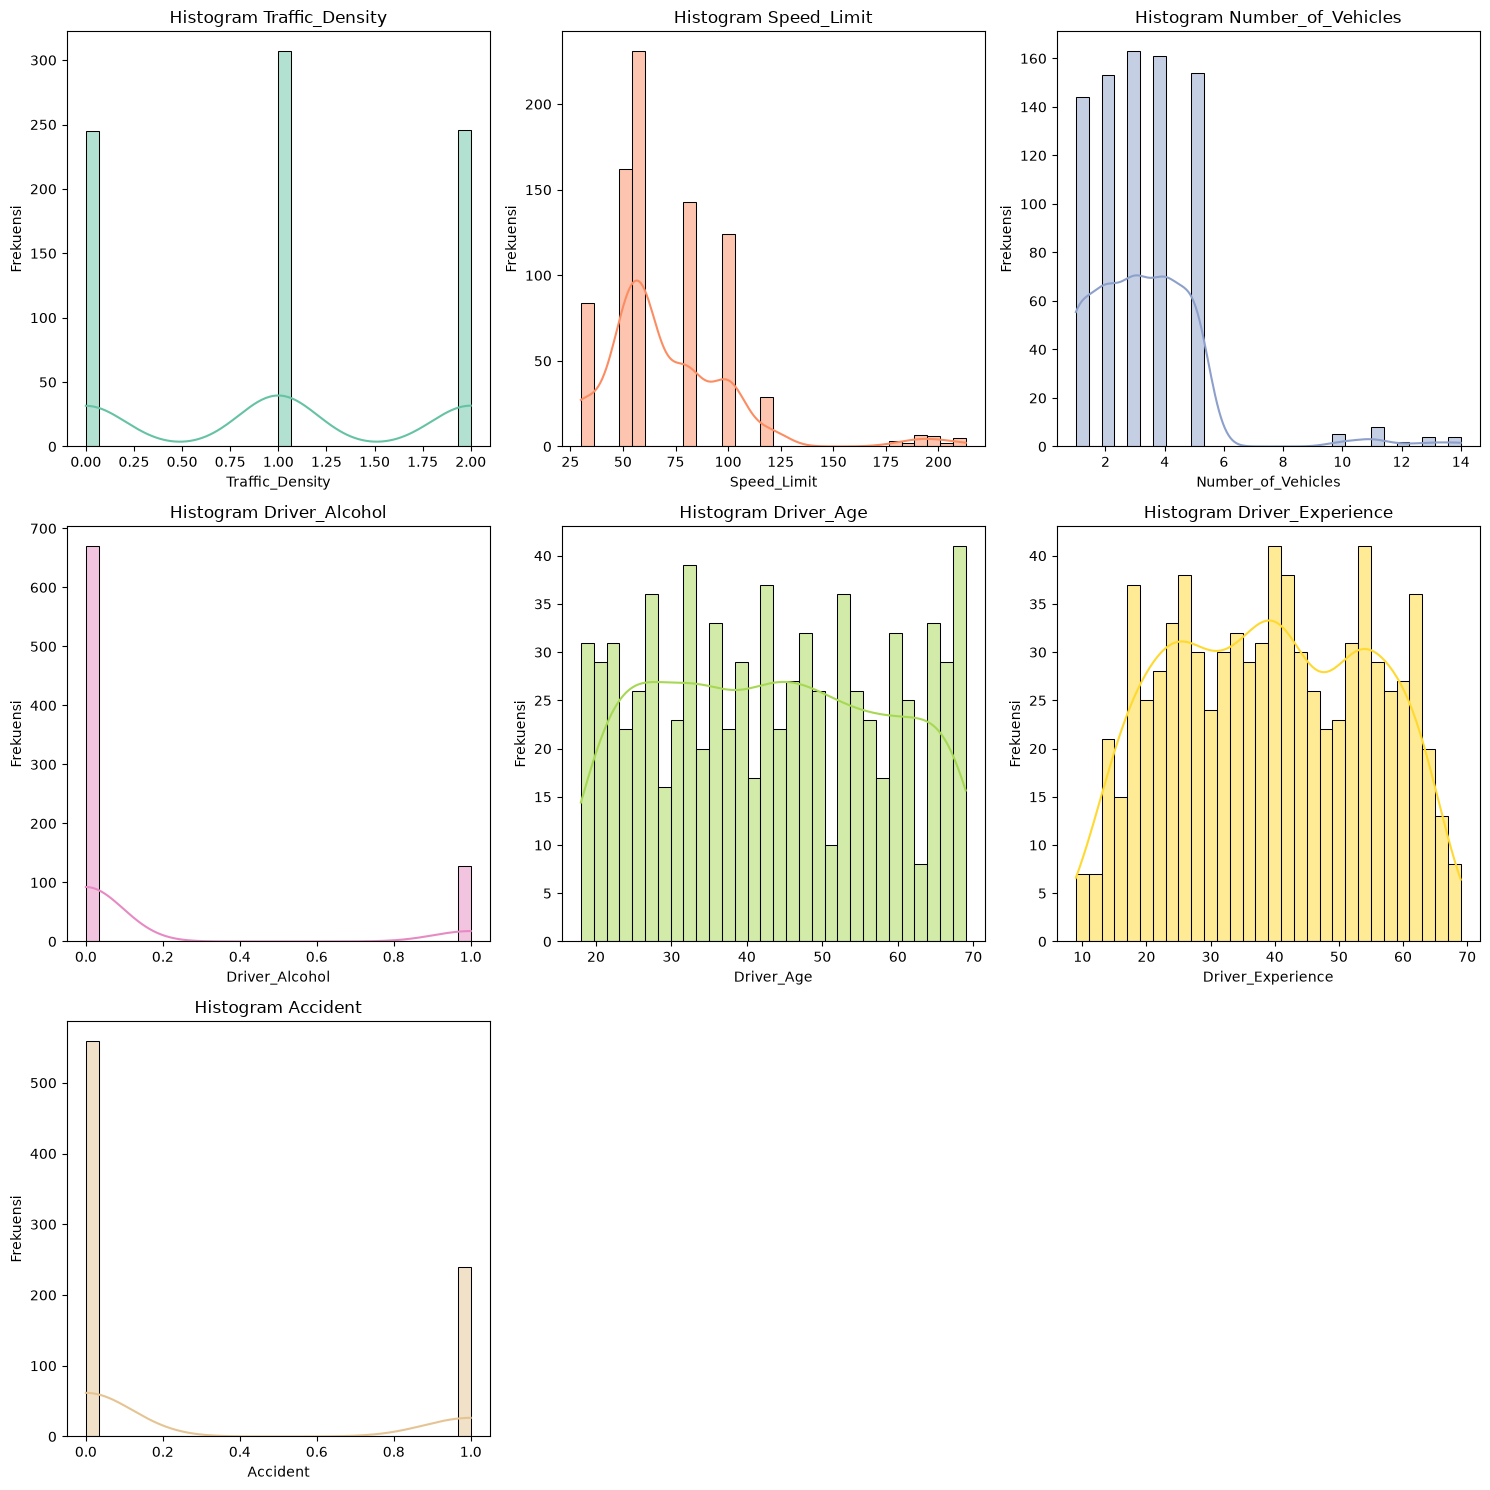

In [209]:
n_cols = 3
n_rows = int(len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = axes.flatten()
colors = sns.color_palette('Set2', len(numeric_cols))

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i], color=colors[i])
    axes[i].set_title(f'Histogram {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

for i in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

### 3.5 Analisis korelasi matrik kolom numerik

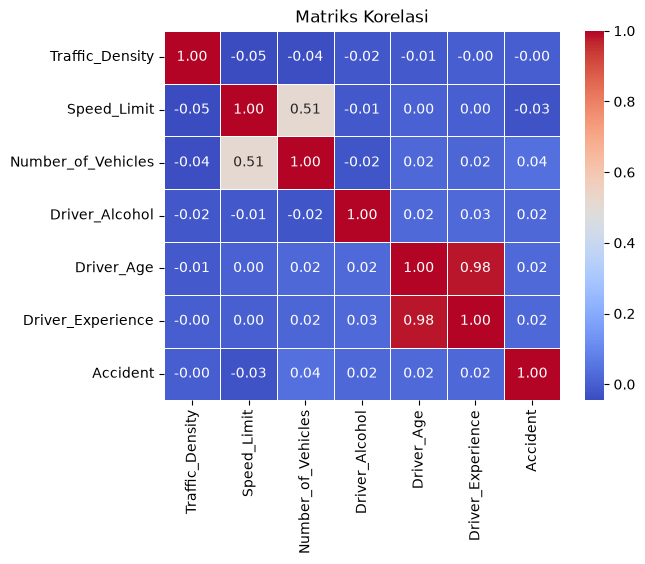

In [210]:
korelsi = df[numeric_cols].corr(method='pearson')
sns.heatmap(korelsi, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi')
plt.show()

### 3.6 Distribusi Kolom Kategorikal

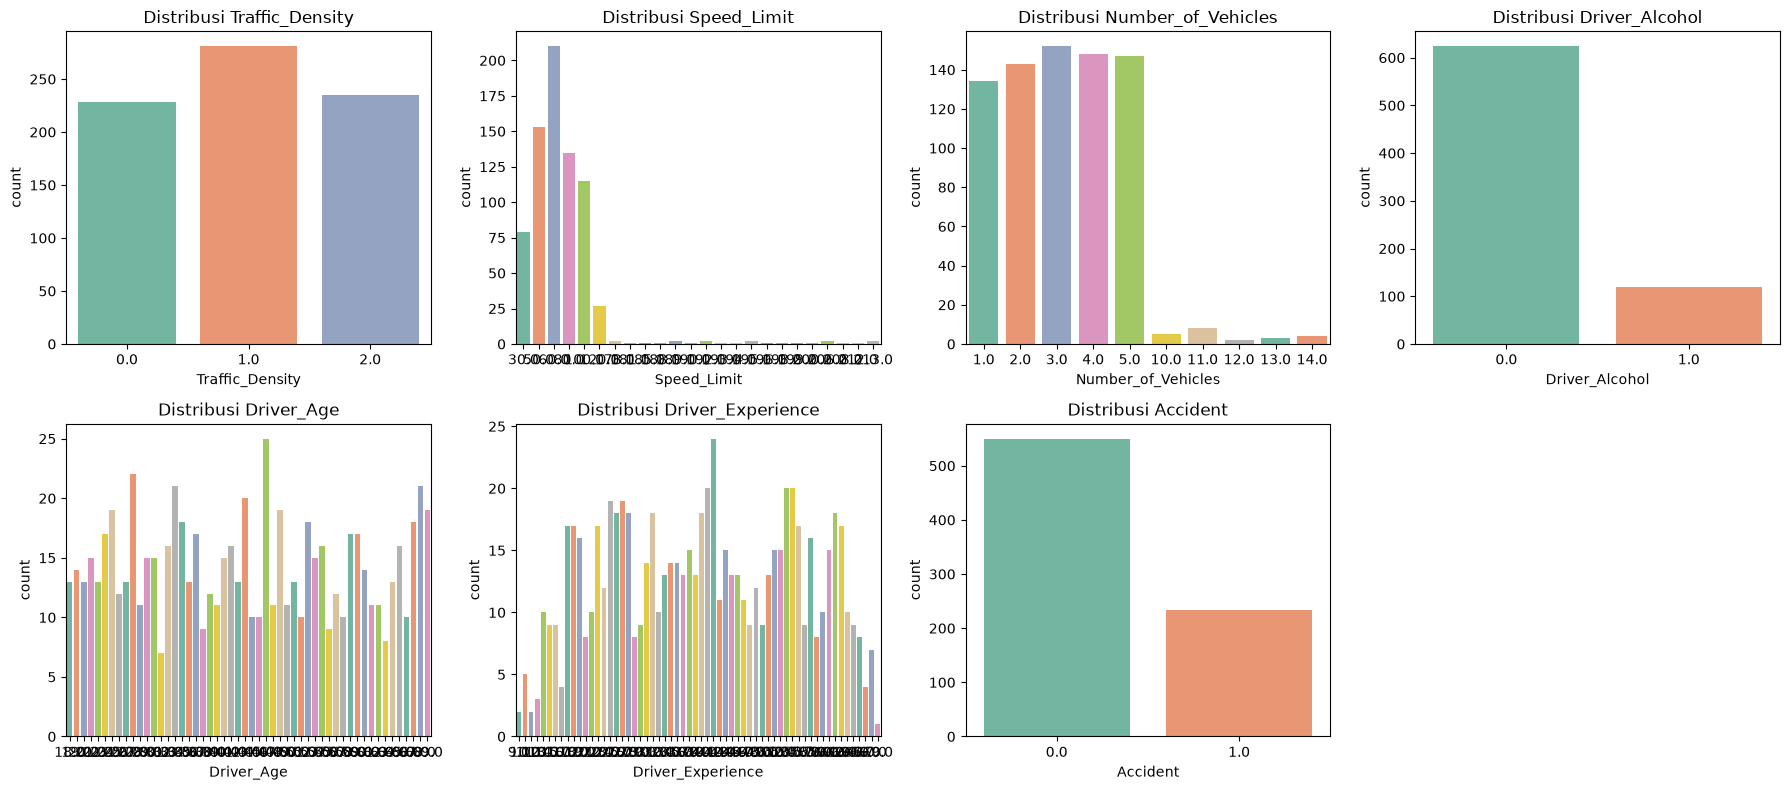

In [225]:
columns = ['Weather', 'Road_Type', 'Time_of_Day', 'Traffic_Density', 'Speed_Limit', 'Road_Condition', 'Vehicle_Type', 'Road_Light_Condition', 'Accident']
n_cols = 4
n_rows = int(len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()
colors = sns.color_palette('Set2', len(numeric_cols))

for i, col in enumerate(numeric_cols):
    sns.countplot(data=df, x=col, ax=axes[i], palette='Set2', hue=col,  legend=False)
    axes[i].set_title(f'Distribusi {col}')

for i in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

---
## 4. Data Preprocessing

### 4.1 Menampilkan kembali missing value dan data duplikat

In [212]:
print(f'-- missing value =-- \n{df.isnull().sum()[df.isnull().sum() > 0]}')
print(f'\njumlah data duplikat = {df.duplicated().sum()}')

-- missing value =-- 
Weather                 42
Road_Type               42
Time_of_Day             42
Traffic_Density         42
Speed_Limit             42
Number_of_Vehicles      42
Driver_Alcohol          42
Accident_Severity       42
Road_Condition          42
Vehicle_Type            42
Driver_Age              42
Driver_Experience       42
Road_Light_Condition    42
Accident                42
dtype: int64

jumlah data duplikat = 14


### 4.2 Menghapus missing value pada kolom target

In [213]:
df = df.drop_duplicates().dropna(subset=['Accident']).reset_index(drop=True)

print(f'jumlah data setelah pembersihan: {df.shape}')

jumlah data setelah pembersihan: (784, 14)


### 4.3 Memisahkan kolom fitur($X$) dan kolom target($y$)

In [214]:
X = df.drop(columns=['Accident'])
y = df['Accident'].astype('int')

### 4.4 Spliting data

In [215]:
np.random.seed(42)
idx_train_list, idx_test_list = [], []

for kelas in np.unique(y):
    idx_kelas = np.where(y == kelas)[0]
    idx_acak = np.random.permutation(idx_kelas)
    batas = int(0.8 * len(idx_acak))
    idx_train_list.append(idx_acak[:batas])
    idx_test_list.append(idx_acak[batas:])

idx_train = np.random.permutation(np.concatenate(idx_train_list))
idx_test = np.random.permutation(np.concatenate(idx_test_list))

X_train = X.iloc[idx_train].copy().reset_index(drop=True)
X_test = X.iloc[idx_test].copy().reset_index(drop=True)
y_train = y.iloc[idx_train].reset_index(drop=True)
y_test = y.iloc[idx_test].reset_index(drop=True)

print(f'jumlah data train: {X_train.shape[0]} baris, {X_train.shape[1]} kolom')
print(f'jumlah data test: {y_test.shape[0]}')

jumlah data train: 627 baris, 13 kolom
jumlah data test: 157


### 4.5 Penanganan missing value pada kolom numerik dan kategorikal

In [ ]:
kolom_kategorikal = ['Weather', 'Road_Type', 'Time_of_Day', 'Traffic_Density', 'Driver_Alcohol', 'Accident_Severity', 'Road_Condition', 'Vehicle_Type', 'Road_Light_Condition']
kolom_numerik = ['Speed_Limit', 'Number_of_Vehicles', 'Driver_Age', 'Driver_Experience']

for col in kolom_kategorikal:
    X_train[col] = X_train[col].fillna(X_train[col].mode()[0])
    X_test[col] = X_test[col].fillna(X_train[col].mode()[0])
    
for col in kolom_numerik:
    X_train[col] = X_train[col].fillna(X_train[col].median())
    X_test[col] = X_test[col].fillna(X_train[col].median())
    
print(f'-- missing value -- \n{X_train.isnull().sum()[X_train.isnull().sum() > 0]}')

-- missing value =-- 
Series([], dtype: int64)


### 4.6 Penangan outlier

In [ ]:
for col in ['Speed_Limit', 'Number_of_Vehicles']:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    X_train[col] = np.clip(X_train[col], lower, upper)
    X_test[col] = np.clip(X_test[col], lower, upper)

### 4.7 Encoding fitur kategorikal

In [218]:
map_saverity = {'Low': 0, 'Moderate': 1, 'High': 2}
map_light = {'No Light': 0, 'Arificial Light': 1, 'Daylight': 2}
kolom_nominal = ['Weather', 'Road_Type', 'Time_of_Day', 'Road_Condition', 'Vehicle_Type']

X_train['Accident_Severity'] = X_train['Accident_Severity'].map(map_saverity)
X_test['Accident_Severity'] = X_test['Accident_Severity'].map(map_saverity)

X_train['Road_Light_Condition'] = X_train['Road_Light_Condition'].map(map_light)
X_test['Road_Light_Condition'] = X_test['Road_Light_Condition'].map(map_light)


X_train = pd.get_dummies(X_train, columns=kolom_nominal, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=kolom_nominal, drop_first=True, dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 627 entries, 0 to 626
Data columns (total 24 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Traffic_Density                    627 non-null    float64
 1   Speed_Limit                        627 non-null    float64
 2   Number_of_Vehicles                 627 non-null    float64
 3   Driver_Alcohol                     627 non-null    float64
 4   Accident_Severity                  627 non-null    int64  
 5   Driver_Age                         627 non-null    float64
 6   Driver_Experience                  627 non-null    float64
 7   Road_Light_Condition               292 non-null    float64
 8   Weather_Foggy                      627 non-null    int64  
 9   Weather_Rainy                      627 non-null    int64  
 10  Weather_Snowy                      627 non-null    int64  
 11  Weather_Stormy                     627 non-null    int64  
 12  Road_

### 4.8 Scaling kolom dengan standarization

In [221]:
for col in kolom_numerik:
    mean = X_train[col].mean()
    std = X_train[col].std()
    X_train[col] = (X_train[col] - mean) / std
    X_test[col] = (X_test[col] - mean) / std

X_train_np = X_train.to_numpy(dtype=float)
X_test_np = X_test.to_numpy(dtype=float)
y_train_np = y_train.to_numpy(dtype=float)
y_test_np = y_test.to_numpy(dtype=float)

df.describe()

,Traffic_Density,Speed_Limit,Number_of_Vehicles,Driver_Alcohol,Driver_Age,Driver_Experience,Accident
count,744.000000,743.000000,746.000000,744.000000,744.000000,743.000000,784.000000
mean,1.009409,71.130552,3.297587,0.161290,43.383065,39.161507,0.298469
std,0.789342,32.257646,2.023996,0.368046,15.164146,15.291887,0.457879
min,0.000000,30.000000,1.000000,0.000000,18.000000,9.000000,0.000000
25%,0.000000,50.000000,2.000000,0.000000,30.000000,26.000000,0.000000
50%,1.000000,60.000000,3.000000,0.000000,43.000000,39.000000,0.000000
75%,2.000000,80.000000,4.000000,0.000000,56.000000,53.000000,1.000000
max,2.000000,213.000000,14.000000,1.000000,69.000000,69.000000,1.000000


<Axes: >

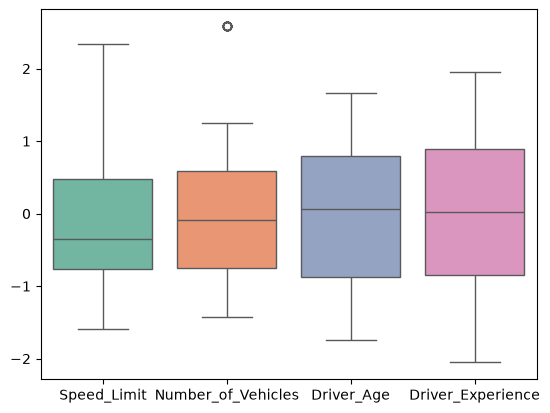

In [220]:
sns.boxplot(data=X_train[kolom_numerik], palette='Set2')